****PRACTICA FINAL IA (YouTube Trending Videos)****

**Preprocesamiento**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle as pkl

Actualizamos la categoria de nuestro fichero csv en base a los datos que tenemos en el fichero JSON.

In [2]:
def actualizacion_categoria_pais(ruta_csv, ruta_json, nombre_pais):

    """Función que actualiza la category_id del Csv reemplazando por el valor string asignado en el fichero json y añade columna con el pais."""
    
    dfjson = pd.read_json(ruta_json)#en vez de leer linea por linea, empaqueta todo el json
    dfjson_aplanado = pd.json_normalize(dfjson['items'])
    dfjson_items = pd.DataFrame({'json_id': dfjson_aplanado['id'].astype(str),'category': dfjson_aplanado['snippet.title']})
    
    dfcsv = pd.read_csv(ruta_csv, encoding='ISO-8859-1')
    dfcsv['category_id'] = dfcsv['category_id'].astype(str)
    
    df_final = pd.merge(dfcsv, dfjson_items, left_on='category_id', right_on='json_id', how='left')
    
    df_final = df_final.drop(columns=['json_id', 'category_id'])

    df_final['pais'] = nombre_pais#creamos la columna pais 
                
    return df_final

In [3]:
paises = {"CA":"Canadá","DE":"Alemania","FR":"Francia","GB":"Gran Bretaña","IN":"India","JP":"Japón","KR":"Corea","MX":"Mexico","RU":"Rusia","US":"USA"}

In [4]:
dataframe_por_pais = (actualizacion_categoria_pais(f"{c}videos.csv", f"{c}_category_id.json", nombre) for c, nombre in paises.items())

Unificamos todos los dataframes

In [5]:
dataframe_final = pd.concat(dataframe_por_pais, ignore_index=True)

Confirmamos que en nuestro dataframe final hay registros de todos los paises.

In [6]:
dataframe_final.pais.value_counts()

pais
USA             40949
Canadá          40881
Alemania        40840
Rusia           40739
Francia         40724
Mexico          40451
Gran Bretaña    38916
India           37352
Corea           34567
Japón           20523
Name: count, dtype: int64

title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

In [7]:
dataframe_final.shape

(375942, 17)

Procedemos a quitar los duplicados.

In [8]:
dataframe_final.drop_duplicates(inplace=True)

In [9]:
dataframe_final.shape

(363372, 17)

Se eliminan alrededor de 12000 duplicados

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador 

Las columnas video_id, description y thumbnail_link  no tiene ningún tipo de información que nos pueda ayudar. Las eliminamos.

In [10]:
dataframe_final.drop(["video_id", "thumbnail_link", "description"], axis=1, inplace=True)

In [11]:
dataframe_final.shape

(363372, 14)

In [12]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 363372 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           363372 non-null  object
 1   title                   363372 non-null  object
 2   channel_title           363372 non-null  object
 3   publish_time            363372 non-null  object
 4   tags                    363372 non-null  object
 5   views                   363372 non-null  int64 
 6   likes                   363372 non-null  int64 
 7   dislikes                363372 non-null  int64 
 8   comment_count           363372 non-null  int64 
 9   comments_disabled       363372 non-null  bool  
 10  ratings_disabled        363372 non-null  bool  
 11  video_error_or_removed  363372 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    363372 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vemos en category que hay algún nulo. Procedemos a eliminarlos

In [13]:
dataframe_final.dropna(inplace=True)

In [14]:
dataframe_final.shape

(360662, 14)

In [15]:
dataframe_final.info()#Confirmamos que se han quitado todos los nulos.

<class 'pandas.core.frame.DataFrame'>
Index: 360662 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           360662 non-null  object
 1   title                   360662 non-null  object
 2   channel_title           360662 non-null  object
 3   publish_time            360662 non-null  object
 4   tags                    360662 non-null  object
 5   views                   360662 non-null  int64 
 6   likes                   360662 non-null  int64 
 7   dislikes                360662 non-null  int64 
 8   comment_count           360662 non-null  int64 
 9   comments_disabled       360662 non-null  bool  
 10  ratings_disabled        360662 non-null  bool  
 11  video_error_or_removed  360662 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    360662 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vamos con title y channel title. Vemos que es un video de tendencias por lo que podria suceder que el mismo video fuera tendencia varios dias 
y por tantos los datos pudieran estar duplicados pero el drop_duplicates no haya funcionado porque las variables numéricas sean diferentes.

In [16]:
df_duplicados_ejemplos = dataframe_final[dataframe_final.duplicated(subset=["title", "channel_title"])]#keep false para valores unicos sin repetir duplicados
df_duplicados_ejemplos.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
200,17.15.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",2649977,193479,3496,17846,False,False,False,Comedy,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
216,17.15.11,STRANGER JOKES : Jokes de Papa avec les teens ...,"Le Jeu, C'est SÃ©rieux",2017-11-13T15:48:57.000Z,"Stranger Jokes|""Jokes de Papa""|""Stranger Thing...",443131,27026,491,746,False,False,False,Comedy,Canadá
218,17.15.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,2017-11-13T17:13:01.000Z,SHANtell martin,2188675,88100,7150,24225,False,False,False,People & Blogs,Canadá
219,17.15.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",4326684,167696,6730,9265,False,False,False,Comedy,Canadá


Los registros que nos aparecen son registros que tienen más de un registro con el mismo nombre y canal. Veamos un ejemplo:

In [17]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. BeyoncÃ©") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
0,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,False,False,False,Music,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
498,17.16.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",22702386,869304,50018,123235,False,False,False,Music,Canadá
791,17.17.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania


Vemos que hay columnas repetidas en las que como pasa aquí fue trending en varias ocasiones. Haremos filtrado y dejaremos un valor único por país teniendo en cuenta principalmente la variable views, ya que a priori a mas alta dicha variable mas likes, dislikes y commments debería haber ya que el formato youtube va acumulando cada dia dichos items. Tenemos en cuenta país ya que un mismo vídeo puede ser tendencia en dos o más países y de cara a nuestro modelo puede ser interesante.

In [18]:
dataframe_final.sort_values(by="views", ascending=False, inplace=True)

dataframe_final.drop_duplicates(subset=["channel_title", "title", "pais"],keep="first",inplace=True)

Una vez ordenados los datos y quitados los duplicados, confirmamos que efectivamente nos ha dejado un valor único por país y si habiendo varios regitros iguales el que más views tiene (ver Canadá por ejemplo)

In [19]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. BeyoncÃ©") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
125227,17.27.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",39235314,1044324,63815,137383,False,False,False,Music,Gran Bretaña
335988,17.18.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",26448434,911883,53873,127481,False,False,False,Music,USA
791,17.17.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania
81791,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem""|""Walk""|""On""|""Water""|""Aftermath/Shady/I...",17158579,787425,43420,125882,False,False,False,Music,Francia
219394,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787426,43420,125882,False,False,False,Music,Corea


In [20]:
dataframe_final.shape#Aligeramos el peso del dataframe.

(207525, 14)

In [21]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           207525 non-null  object
 1   title                   207525 non-null  object
 2   channel_title           207525 non-null  object
 3   publish_time            207525 non-null  object
 4   tags                    207525 non-null  object
 5   views                   207525 non-null  int64 
 6   likes                   207525 non-null  int64 
 7   dislikes                207525 non-null  int64 
 8   comment_count           207525 non-null  int64 
 9   comments_disabled       207525 non-null  bool  
 10  ratings_disabled        207525 non-null  bool  
 11  video_error_or_removed  207525 non-null  bool  
 12  category                207525 non-null  object
 13  pais                    207525 non-null  object
dtypes: bool(3), int64(4), object(7)
memo

Procedemos a pasar trending date y publish time a formato datetime y creamos una columna que indica los numeros de días que pasaron desde que se publicó hasta que fue trending. Una vez se ha creado la columna, eliminamos ambas columnas.

In [23]:
import pandas as pd


dataframe_final["trending_date"] = pd.to_datetime(dataframe_final["trending_date"], format="%y.%d.%m", errors="coerce").dt.floor('D')


dataframe_final["publish_time"] = pd.to_datetime(dataframe_final["publish_time"], errors="coerce").dt.tz_localize(None).dt.floor('D')


dataframe_final["dias_desde_publicacion"] = (dataframe_final["trending_date"] - dataframe_final["publish_time"]).dt.days.clip(lower=0)



In [24]:
dataframe_final.drop(["trending_date","publish_time"], axis=1, inplace=True)

In [25]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"Bad Bunny|""Amorfoda""|""Dura""|""Daddy Yankee""|""Oz...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,36
156905,"Te Bote Remix - Casper, Nio GarcÃ­a, Darell, N...",Flow La Movie,"Te Bote|""Te Bote Remix""|""Flow La Movie""|""Ozuna...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,37
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"Bad|""Bunny""|""Bad Bunny""|""Video Oficial""|""Music...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,36
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"Ozuna|""Reggaeton""|""Odisea""|""Odisea The Album""|...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,30
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"Childish Gambino|""Rap""|""This Is America""|""mcDJ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,36


Vamos a modificar los formatos de cada columna. Comenzaremos con title de tipo string. Procedemos a quitar los espacios 
y los posibles saltos de línea al introducir el nombre del title.

In [26]:
dataframe_final["title"] = (dataframe_final["title"].str.strip().str.split().str.join(" "))

Realizamos la misma transformación en channel_title:

In [27]:
dataframe_final["channel_title"] = (dataframe_final["channel_title"].str.strip().str.split().str.join(" "))

En el caso de tags además de los espacios en blanco, debemos de quitar "|" para que el modelo pueda leerlo mejor. 
Metemos los datos en una lista.

In [28]:
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split().str.join(" "))
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split("|", regex=False))

In [29]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, ""Amorfoda"", ""Dura"", ""Daddy Yankee""...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,36
156905,"Te Bote Remix - Casper, Nio GarcÃ­a, Darell, N...",Flow La Movie,"[Te Bote, ""Te Bote Remix"", ""Flow La Movie"", ""O...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,37
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, ""Bunny"", ""Bad Bunny"", ""Video Oficial"", ""...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,36
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, ""Reggaeton"", ""Odisea"", ""Odisea The Alb...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,30
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, ""Rap"", ""This Is America"", ""...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,36


Limpio el dataset, lo guardamos en formato pickle y  pasamos al análisis exploratorio

In [30]:
dataframe_final.to_pickle("dataframe_final_limpio.pkl")

**Analisis exploratorio**

A continuación vamos a ver un poco los datos que tenemos después de procesar nuestro df. Para esta parte lo pasamos a pandas.

In [31]:
df = pd.read_pickle("dataframe_final_limpio.pkl")

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   title                   207525 non-null  object
 1   channel_title           207525 non-null  object
 2   tags                    207525 non-null  object
 3   views                   207525 non-null  int64 
 4   likes                   207525 non-null  int64 
 5   dislikes                207525 non-null  int64 
 6   comment_count           207525 non-null  int64 
 7   comments_disabled       207525 non-null  bool  
 8   ratings_disabled        207525 non-null  bool  
 9   video_error_or_removed  207525 non-null  bool  
 10  category                207525 non-null  object
 11  pais                    207525 non-null  object
 12  dias_desde_publicacion  207525 non-null  int64 
dtypes: bool(3), int64(5), object(5)
memory usage: 18.0+ MB


In [33]:
matriz_correlacion = df.corr(numeric_only=True)#sacamos la matriz de correlacion para vaer relacion de las variables numéricas

In [34]:
print(matriz_correlacion)

                           views     likes  dislikes  comment_count  \
views                   1.000000  0.747095  0.442746       0.528759   
likes                   0.747095  1.000000  0.429676       0.803652   
dislikes                0.442746  0.429676  1.000000       0.637617   
comment_count           0.528759  0.803652  0.637617       1.000000   
comments_disabled      -0.006558 -0.022285 -0.006149      -0.022113   
ratings_disabled       -0.011216 -0.027856 -0.011366      -0.015297   
video_error_or_removed  0.006401  0.007036  0.002517       0.003513   
dias_desde_publicacion  0.009653  0.004343  0.001854       0.001563   

                        comments_disabled  ratings_disabled  \
views                           -0.006558         -0.011216   
likes                           -0.022285         -0.027856   
dislikes                        -0.006149         -0.011366   
comment_count                   -0.022113         -0.015297   
comments_disabled                1.000000    

Conclusiones:  

Likes y comment_count: Si hay un like, suele haber un comentario de manera generalizada.

Views y likes: A más visualizaciones más likes. Por lo tanto views, likes y comment_count suelen ir de la mano.

Dislikes con views, likes y comment_count: Cuanto más se ve el video, más posibles dislikes puede provocar y por tanto, mas comentarios a modo de hate.

In [35]:
df.describe()

,views,likes,dislikes,comment_count,dias_desde_publicacion
count,2.075250e+05,2.075250e+05,2.075250e+05,2.075250e+05,207525.000000
mean,5.340433e+05,1.626300e+04,9.406069e+02,2.005660e+03,4.020870
std,3.279155e+06,8.822365e+04,1.250509e+04,1.409846e+04,62.406812
min,1.530000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.581900e+04,3.750000e+02,2.300000e+01,6.000000e+01,1.000000
50%,9.312400e+04,1.732000e+03,9.400000e+01,2.710000e+02,1.000000
75%,3.247840e+05,7.470000e+03,3.720000e+02,1.041000e+03,2.000000
max,4.245389e+08,5.613827e+06,1.944971e+06,1.626501e+06,4215.000000


Podemos ver que los valores máximos y minimos distorsionan mucho con respecto a la media y si intentamos sacar outliers, vemos 
que hay en las variables views, likes, dislikes, comment_count y dias desde publicación. Esto es debido a la viralidad que se puede dar con cierto vídeo. Vamos a representar los outliers de views ya que como vimos anteriormente a partir de ella el resto de outliers que hemos visto también pueden aumentar dada su gran relación.

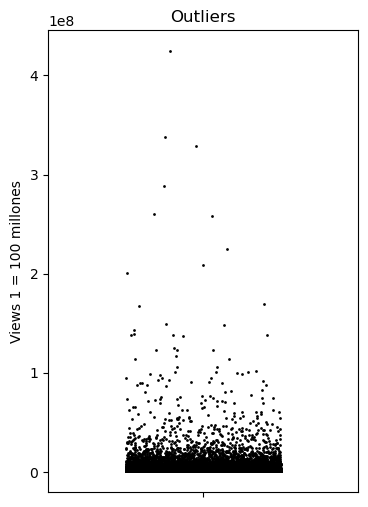

In [36]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1 #Rango intercuantílico
limite_outliers = Q3 + (1.5 * IQR)
df_outliers = df[df["views"] > limite_outliers]

plt.figure(figsize=(4, 6))
sns.stripplot(y=df_outliers["views"], color="black", jitter=0.25,size=2)

plt.title("Outliers")
plt.ylabel("Views 1 = 100 millones")
plt.show()

Vemos claramente los outliers y de cara al EDA los dejamos ya que según que planteamiento puede ser bueno quitarlos o no.

Vimos anteriormente también que hay en dias desde publicación valores negativos. Los contabilizamos.

In [ ]:
(df["dias_desde_publicacion"] < 0).sum()

**Analisis univariado de variables categoricas**

In [ ]:
df.category.value_counts(normalize=True)

Vemos que más de la mitad de los videos son de la categoría Entertainment, People & Blogs y News & Politics.

In [ ]:
df.category.value_counts(normalize=True).plot.barh()
plt.show()

In [ ]:
df.pais.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que lo datos se centran sobre todo en los paises Rusia, Mexico, Alemania, Francia y Canada

In [ ]:
df['comments_disabled'].value_counts()

In [ ]:
df['ratings_disabled'].value_counts()

In [ ]:
df['video_error_or_removed'].value_counts()

In [ ]:
df.drop('video_error_or_removed', axis=1, inplace=True)

Vemos que no tiene ningún valor esta variable por lo que la eliminamos ahora aquí e insertamos la actualización el fichero preprocess.

In [ ]:
df.sort_values(by='views', ascending=False).head(10)

Vemos que hay videos que han sido tendencia en diferentes países.

**Analisis bivariado de variables categoricas**

In [ ]:
df.pivot_table(index="pais", columns="category", values="views")

In [ ]:
pivot_views = df.pivot_table(index="pais", columns="category", values="views")
plt.figure(figsize=(14, 7))

sns.heatmap(pivot_views, cmap="Blues", annot=False, linewidths=0.5)

plt.title("Views por país y categoría",fontsize=15)
plt.xlabel("Categorías de Video", fontsize=11)
plt.ylabel("Países", fontsize=11)
plt.xticks(rotation=45, ha="right") 

plt.tight_layout()
plt.show()

Vemos que las mayorias de visualizaciones se dan en Gran Bretaña y EEUU y que la categoría que más views suele tener es Music. El hecho de que un video sea de Gran Bretaña y de Musica puede ser relevante por ejemplo para el modelo, por lo que ambas categorías es bueno tenerlas en cuenta.

Vamos a desglosar comments_disabled	y ratings_disable. Estas dos variables la mayoría del tiempo son False ya que lo normal es querer que la gente comente y haga like o dislike a tus videos. Vamos a ver en cuantos casos desactivaron ambas variables.

In [ ]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]

In [ ]:
Desactivadas.shape

In [ ]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]
Activadas = df[(df["comments_disabled"] == False) & (df["ratings_disabled"] == False)]

promedio_desactivadas = Desactivadas[["views"]].mean()# Calculamos los promedios de 'views' y 'likes' para ambos grupos
promedio_activadas = Activadas[["views"]].mean()

# 4. Juntamos ambos resultados en una pequeña tabla para comparar de reojo
comparativa_directa = pd.DataFrame({"Ambas Activadas": promedio_activadas, "Ambas Desactivadas": promedio_desactivadas}).T #Transponemos para que se cambien columnas y filas

print(comparativa_directa)

Vemos que cuando los comentarios y los ratings estan deshabilitados, suele haber mas visualizaciones por parte de los usuarios. Normalmente este tipo de sucesos se dan porque los videos suelen ser polémicos y los creadores de contenido quitan los comentarios y las interacciones.

In [ ]:
intervalos = [-1, 0, 1, 7, 30, 365, float("inf")]
etiquetas = ["Mismo día", "1 día", "2-7 días", "8-30 días",
             "31-365 días", "Más de 1 año"]

dataframe_final["intervalo_antiguedad"] = pd.cut(
    dataframe_final["dias_desde_publicacion"],
    bins=intervalos,
    labels=etiquetas
)

dataframe_final["intervalo_antiguedad"].value_counts(
    sort=False,
    normalize=True
).mul(100).round(1)

Vimos que de media los videos suelen tardar unos 4 días en ser tendencia, aunque la mediana nos indica que suelen tardar alrededor de 1 dia. La dispersión es grande y se puede ver porque por ejemplo el vídeo máximo tardo 4215 dias en ser tendencia algo poco común.

Las conclusiones que podemos sacar son las siguientes:
1. Existe una relación clara entre los views, los coments y los likes/dislikes.
2. Entertainment, People & Blogs y News & Politics son las categorías que más destacan.
3. Un mismo vídeo puede ser viral en varios países.
4. Existe una relación directamente proporcional entre bloquear los comentarios y los ratings y las visualizaciones.
5. Cruzando datos vemos que los videos que más views han tenido son de Musica fundamentalmente en Reino Unido. Tanto Reino Unido como el tipo Musica muestran ser una de las piezas fundamentales sobre las que giran las visualizaciones.

A continuación vamos a pasar a realizar punto por punto lo solicitado en los modelos.

**Predecir categoria del video**

Vamos a utilizar los modelos conocidos pero en primer lugar vamos a rescatar el dataset limpio en formato parquet (lo hemos estado trabajando en pandas para el EDA), con el fin de ganar mayor rendimiento con Spark ML

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

Regresión logística

In [ ]:
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline

In [ ]:
columnas_categoricas = ["category", "pais"]
indexer = StringIndexer(inputCols=columnas_categoricas, outputCols=[f"{c}_indexado" for c in columnas_categoricas], handleInvalid="keep")
#Hacemos el string indexer para las variables categóricas, category y pais, para poder usarlas en el modelo de regresión logística.

In [ ]:
encoder = OneHotEncoder(inputCols=["pais_indexado"],outputCols=["pais_encoded"])
#Hacemos el one hot encoder para la variable pais_indexado  , para poder usarla en el modelo de regresión logística. 
#No usamos category ya que es la variable objetivo

In [ ]:
#Cogemos las columnas predictoras y las juntamos en una sola columna llamada features, que es la que usará el modelo de regresión logística.
features = ["pais_encoded", "views_log", "likes_log", "dislikes_log", "comment_count_log", "comments_disabled", "ratings_disabled"]
Assembler = VectorAssembler(inputCols=features, outputCol="features_brutas")

In [ ]:
scaler = StandardScaler(inputCol="features_brutas", outputCol="features_scaled", withStd=True, withMean=False)

In [ ]:
lr = LogisticRegression(featuresCol="features_scaled", labelCol="category_indexado")

In [ ]:
Pipeline_lr = Pipeline(stages=[indexer, encoder, Assembler,scaler,lr])
Pipeline_model = Pipeline_lr.fit(df_train_transformado)
df_transformado = Pipeline_model.transform(df_test_transformado)

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
#Al estar los datos de categorias desbalanceados, usamos la métrica weightedF1 para evaluar cual es mejor opción de los 
#modelos que usaremos de clasifiacion
evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="f1")
weightedF1 = evaluator.evaluate(df_transformado)
print("f1:", weightedF1)


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="accuracy")
accuracy = evaluator.evaluate(df_transformado)
print("Accuracy:", accuracy)

El modelo no está rindiendo correctamente. Vamos a verlo en la matriz de confusión

In [ ]:
df_transformado.stat.crosstab("category_indexado", "prediction").toPandas()

Vemos que el modelo tiende a predecir 0 con bastante facilida. Por ejemplo cuando el valor fue 0 acertó mucho pero cuando fue 1 predijo más veces 0 que 1 y por lo tanto no sería una opción válida a optimizar.

Random Forest

In [ ]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline as RFPipeline

rf = RandomForestClassifier(featuresCol="features_brutas", labelCol="category_indexado", numTrees=100, maxDepth=5, seed=42)
Pipeline_rf = RFPipeline(stages=[indexer, encoder, Assembler,rf])
Pipeline_model_rf = Pipeline_rf.fit(df_train_transformado)
df_transformado_rf = Pipeline_model_rf.transform(df_test_transformado)


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="f1")
weightedF1 = evaluator.evaluate(df_transformado_rf)
print("f1:", weightedF1)

evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="accuracy")
accuracy = evaluator.evaluate(df_transformado_rf)
print("Accuracy:", accuracy)

GBT

In [ ]:
from pyspark.ml.classification import GBTClassifier, OneVsRest  
from pyspark.ml import Pipeline as GBTpipeline
gbt = GBTClassifier(featuresCol="features_brutas", labelCol="category_indexado", maxIter=5, maxDepth=2)
ovr_gbt = OneVsRest(classifier=gbt, labelCol="category_indexado", featuresCol="features_brutas")
Pipeline_gbt = GBTpipeline(stages=[indexer, encoder, Assembler,ovr_gbt])
df_transformado_gbt = Pipeline_gbt.fit(df_train_transformado).transform(df_test_transformado)

In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="f1")
weightedF1 = evaluator.evaluate(df_transformado_gbt)
print("f1:", weightedF1)

evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="accuracy")
accuracy = evaluator.evaluate(df_transformado_gbt)
print("Accuracy:", accuracy)

SVC

In [ ]:
from pyspark.ml.classification import LinearSVC
from pyspark.ml import Pipeline as SVCPipeline
svc = LinearSVC(featuresCol="features_scaled ", labelCol="category_indexado")
ovr_svc = OneVsRest(classifier=svc,featuresCol="features_scaled ",labelCol="category_indexado")
Pipeline_svc = SVCPipeline(stages=[indexer, encoder, Assembler,scaler, ovr_svc])
Pipeline_model_svc = Pipeline_svc.fit(df_train_transformado)
df_transformado_svc = Pipeline_model_svc.transform(df_test_transformado)

In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="f1")
weightedF1 = evaluator.evaluate(df_transformado_svc)
print("f1:", weightedF1)

evaluator = MulticlassClassificationEvaluator(labelCol="category_indexado",predictionCol="prediction",metricName="accuracy")
accuracy = evaluator.evaluate(df_transformado_svc)
print("Accuracy:", accuracy)

**Predecir el número de likes**

**Encontrar grupos en los vídeos mediante diversas técnicas de clusterización**

**Crear un recomendador**

""title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador

[('title', 'string'), 
 ('channel_title', 'string'),
 ('pais', 'string'),
 ('views', 'int'),
 ('tags', 'string'),
 ('likes', 'int'),
 ('dislikes', 'int'),
 ('comment_count', 'int'),
 ('comments_disabled', 'boolean'),
 ('ratings_disabled', 'boolean'),
 ('video_error_or_removed', 'boolean'),
 ('description', 'string'),
 ('category', 'string'),
 ('month_trending', 'int'),
 ('month_publish', 'int')]"""
 • ¿Estás clasificando categorías? Usa Regresión Logística, Árboles de decisión, KNN o SVM.
• ¿Estás prediciendo un número? Usa Regresión Lineal o Árboles de decisión (Regresores).
• ¿Tus datos no tienen etiquetas (no sabes la respuesta)? Usa Clustering o Reducción de dimensionalidad.